# Tutorial 7: Quality, Validation, and Repair

**What You Will Build:** a mesh check and repair pass that finds duplicate
points, zero-area cells, holes, and flipped winding, and fixes them.

Meshes from CAD exports, scanners, and solvers often have such defects. This
tutorial covers the following tasks:

- Measure cell quality and summarize a mesh with `quality_metrics` and
  `statistics`
- Find defects with `validate()`, `is_watertight()`, and `is_manifold()`
- Repair them with `clean()`, `repair_mesh()`, `fix_orientation()`, and
  `fill_holes()`

Needs [Tutorial 1](tutorial_1_getting_started.ipynb) and
[Tutorial 4](tutorial_4_operations.ipynb). Runs on a CPU in a few seconds.

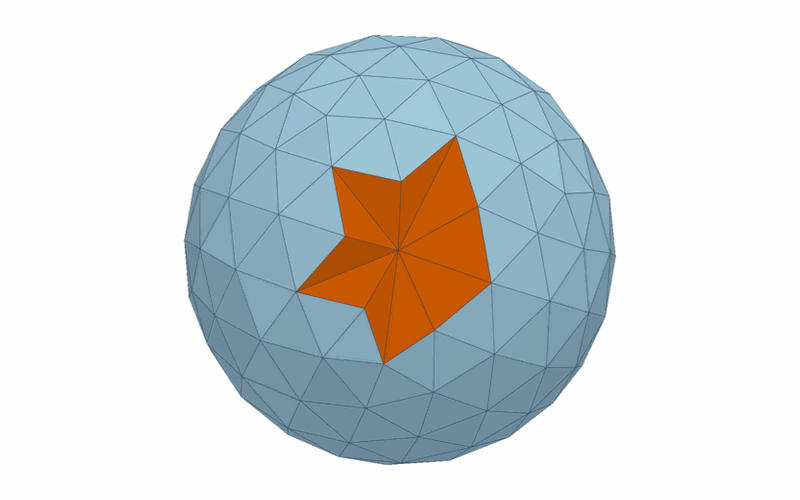

In [1]:
from IPython.display import Image

Image(filename="../../../docs/img/mesh/thumbnails/repair.png", width=480)

In [2]:
import pyvista as pv
import torch

from physicsnemo.mesh import Mesh
from physicsnemo.mesh.io import to_pyvista
from physicsnemo.mesh.primitives.procedural import lumpy_sphere
from physicsnemo.mesh.primitives.surfaces import mobius_strip, sphere_icosahedral
from physicsnemo.mesh.primitives.volumes import cube_volume
from physicsnemo.mesh.repair import fill_holes, fix_orientation, repair_mesh

pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 400]

## 1. Cell Quality Metrics

Badly shaped cells hurt numerical methods. A thin triangle makes cotangent
weights and least-squares gradients ill-conditioned. A mesh with a wide
spread of cell sizes is also harder for a model to learn from. The
`quality_metrics` property measures the shape of every cell.

In [3]:
mesh = sphere_icosahedral.load(subdivisions=2)
metrics = mesh.quality_metrics
print(f"{mesh.n_cells} cells, metrics: {list(metrics.keys())}")

320 cells, metrics: ['aspect_ratio', 'edge_length_ratio', 'min_angle', 'max_angle', 'min_edge_length', 'max_edge_length', 'quality_score']


`quality_metrics` is a `TensorDict` with one row for each cell:

| Metric | Ideal Value | Meaning |
|--------|-------------|---------|
| `aspect_ratio` | 1.0 | Longest edge divided by shortest altitude, normalized so that a regular simplex gives 1. Larger is worse. |
| `edge_length_ratio` | 1.0 | Longest edge divided by shortest edge. |
| `min_angle`, `max_angle` | π/3 for a triangle | Smallest and largest interior angle at a vertex, in radians. For tetrahedra, these are solid angles in steradians. |
| `min_edge_length`, `max_edge_length` | - | Shortest and longest edge, in mesh units. |
| `quality_score` | 1.0 | Geometric mean of edge uniformity, aspect quality, and angle quality, in [0, 1]. |

In [4]:
for key in ("aspect_ratio", "edge_length_ratio", "min_angle", "quality_score"):
    values = metrics[key]
    print(
        f"{key:18s} min={values.min():.3f}  mean={values.mean():.3f}  max={values.max():.3f}"
    )

aspect_ratio       min=1.000  mean=1.084  max=1.243
edge_length_ratio  min=1.000  mean=1.062  max=1.166
min_angle          min=0.948  mean=1.008  max=1.047
quality_score      min=0.845  mean=0.941  max=1.000


An icosahedral sphere is close to ideal, but not perfect, because projecting
the subdivided icosahedron onto the sphere stretches some triangles. A
distorted surface shows a wider spread. `lumpy_sphere` moves the 12 vertices
of an icosahedron by random radial factors, then refines it with Loop
subdivision. The factors are seeded, so the result is reproducible.

In [5]:
regular = sphere_icosahedral.load(subdivisions=3)
lumpy = lumpy_sphere.load(noise_amplitude=0.3, subdivisions=3, seed=42)

for name, m in [("regular", regular), ("lumpy", lumpy)]:
    q = m.quality_metrics["quality_score"]
    m.cell_data["quality"] = q
    print(f"{name:8s} quality_score: min={q.min():.3f}  mean={q.mean():.3f}")

regular  quality_score: min=0.838  mean=0.947
lumpy    quality_score: min=0.632  mean=0.861


Draw both on one color scale. Warm colors mark the lowest scores.

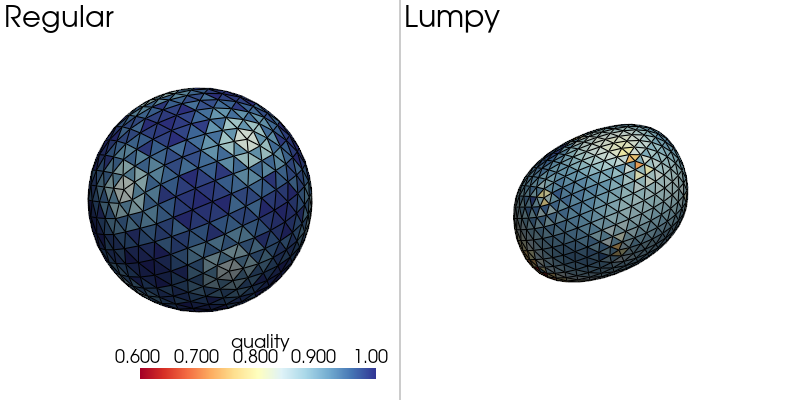

In [6]:
plotter = pv.Plotter(shape=(1, 2))
for column, (title, m) in enumerate([("Regular", regular), ("Lumpy", lumpy)]):
    plotter.subplot(0, column)
    m.draw(
        cell_scalars="quality",
        cmap="RdYlBu",
        vmin=0.6,
        vmax=1.0,
        alpha_points=0.0,
        ax=plotter,
        show=False,
    )
    plotter.add_text(title, font_size=12)
plotter.link_views()
plotter.show()

A threshold on `quality_score` selects the cells to inspect or to fix, for
example, with remeshing. Refer to the
[remeshing API reference](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/remeshing.html).

In [7]:
poor = lumpy.quality_metrics["quality_score"] < 0.75
print(f"Lumpy cells with quality_score < 0.75: {poor.sum().item()} of {lumpy.n_cells}")

Lumpy cells with quality_score < 0.75: 108 of 1280


## 2. Summary Statistics

Before you train on a dataset, you want one summary for each mesh: how many
cells, how large, and how well shaped. The `statistics` property gives this
summary in one call. Each `*_stats` entry is a tuple `(min, mean, max, std)`.

In [8]:
bunny = torch.load("assets/bunny.pt", weights_only=False)

for key, value in bunny.statistics.items():
    if isinstance(value, tuple):
        print(f"{key:22s} " + ", ".join(f"{v:.3g}" for v in value))
    else:
        print(f"{key:22s} {value}")

n_points               400
n_cells                792
n_manifold_dims        2
n_spatial_dims         3
n_degenerate_cells     0
n_isolated_vertices    0
cell_area_stats        0.000102, 0.000266, 0.000501, 6.11e-05
edge_length_stats      0.0111, 0.0255, 0.045, 0.00465
aspect_ratio_stats     1.01, 1.43, 2.75, 0.283
quality_score_stats    0.404, 0.751, 0.993, 0.109


## 3. Validating a Mesh

Sections 3 to 5 follow one pattern: find a defect, then repair it. The figure
shows five common defects, the call that finds each one (top), and the call
that repairs it (bottom).

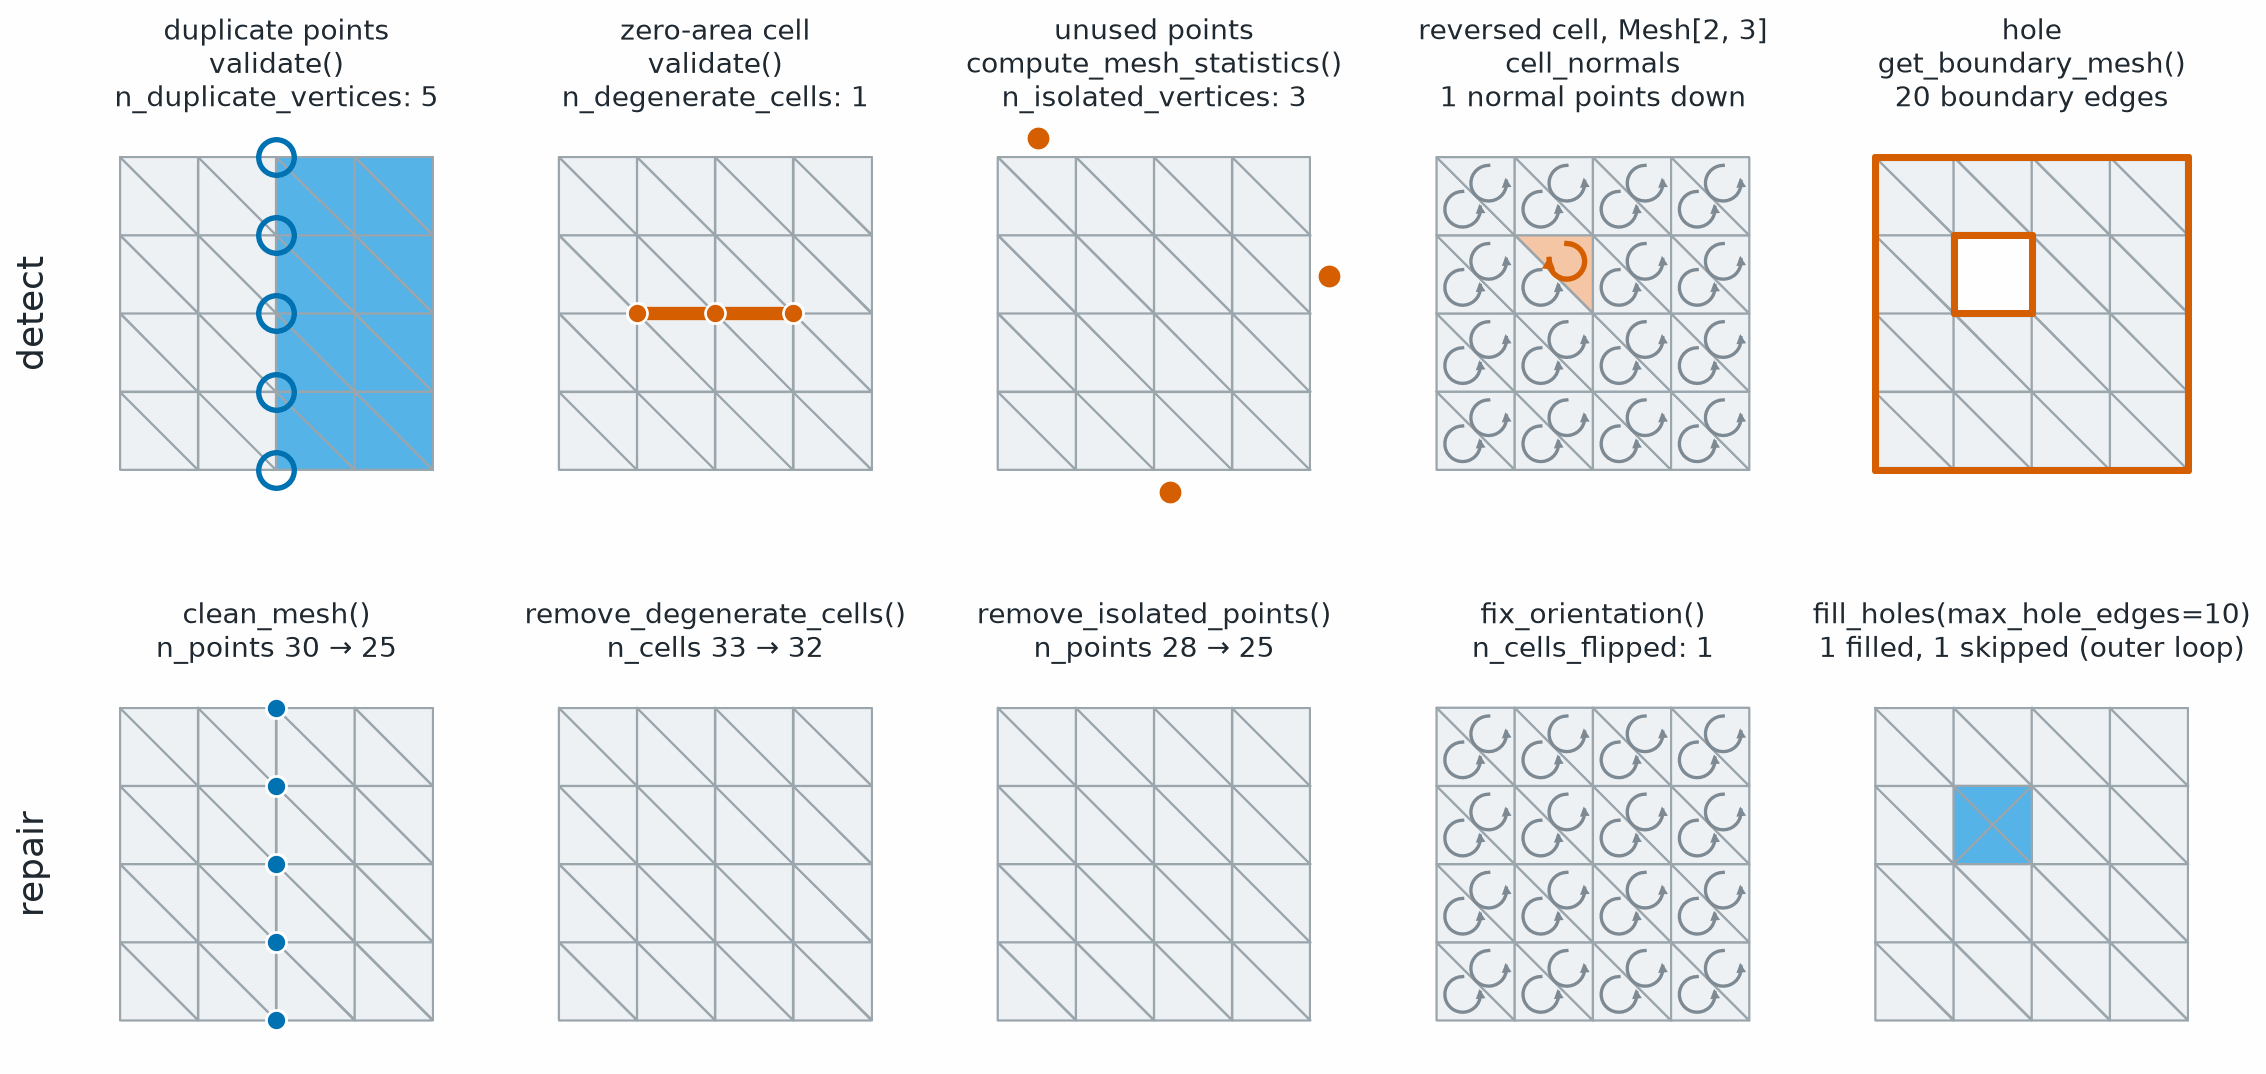

In [9]:
Image(filename="../../../docs/img/mesh/mesh_defects.png", width=900)

| Defect | Found by | Repaired by |
|--------|----------|-------------|
| Duplicate points | `validate()` | `clean()`, `repair_mesh()` |
| Zero-area cells | `validate()` | `repair_mesh()` |
| Unused points | `statistics` | `clean()`, `repair_mesh()` |
| Reversed cells | `cell_normals` | `fix_orientation()` |
| Holes | `is_watertight()`, `get_boundary_mesh()` | `fill_holes()` |

`validate()` returns a dictionary report and, by default, raises nothing.
Three checks run by default: `check_out_of_bounds` (cell indices that do not
refer to a point), `check_duplicate_vertices` (points closer than
`tolerance`), and `check_degenerate_cells` (cells smaller than
`tolerance ** n_manifold_dims`). Two costlier checks are off by default:
`check_inverted_cells` (negative signed volume, for meshes whose cells fill
their space) and `check_manifoldness` (edges shared by more than two
triangles).

In [10]:
report = mesh.validate()
print(report)

{'valid': True, 'n_out_of_bounds_cells': 0, 'n_duplicate_vertices': 0, 'n_degenerate_cells': 0}


Now make a small 2D mesh with two defects. Point 4 duplicates point 0, and
the second cell repeats a vertex, so its area is zero.

In [11]:
points = torch.tensor(
    [
        [0.0, 0.0],
        [1.0, 0.0],
        [0.5, 1.0],
        [0.5, 0.5],
        [0.0, 0.0],  # duplicate of point 0
    ]
)
cells = torch.tensor(
    [
        [0, 1, 2],
        [0, 0, 1],  # degenerate: vertex 0 appears twice
    ]
)
bad_mesh = Mesh(points=points, cells=cells)

report = bad_mesh.validate()
for key, value in report.items():
    print(f"{key:24s} {value}")

valid                    False
n_out_of_bounds_cells    0
n_duplicate_vertices     1
duplicate_vertex_pairs   tensor([[0, 4]])
n_degenerate_cells       1
degenerate_cell_indices  tensor([1])
degenerate_cell_areas    tensor([0.])


The report names the offenders: the duplicate pair `[0, 4]` and the
degenerate cell `1`. Note that `n_duplicate_vertices` counts pairs of
coincident points, not points.

In a data pipeline, you usually want to stop at the first bad sample. Pass
`raise_on_error=True` to raise a `ValueError` instead of returning the report.

In [12]:
try:
    bad_mesh.validate(raise_on_error=True)
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: Found 1 pairs of duplicate vertices (within tolerance=3.2927225399135965e-10).
First few pairs: [[0, 4]]


## 4. Topology Checks: Watertight and Manifold

`validate()` looks at indices and cell sizes, not at topology. Inside-outside
tests and signed distance fields need a closed surface, and normals and
curvature need a manifold. The two checks use the following definitions:

- A mesh is *watertight* if every facet is shared by exactly two cells, so it
  has no boundary. A facet is a face of a cell one dimension down: an edge of
  a triangle, or a triangle of a tetrahedron.
- A mesh is *manifold* if the neighborhood of every point looks like a disk (a
  ball, for a volume mesh). On the boundary, it looks like half of one. An
  open sheet can be manifold without being watertight.

In [13]:
sphere = sphere_icosahedral.load(subdivisions=2)
hemisphere = sphere.slice_cells(sphere.cell_centroids[:, 2] > 0)

for name, m in [("sphere", sphere), ("hemisphere", hemisphere)]:
    print(f"{name:10s} watertight={m.is_watertight()}  manifold={m.is_manifold()}")

sphere     watertight=True  manifold=True
hemisphere watertight=False  manifold=True


The hemisphere is manifold but not watertight. Its boundary is the equator.
`get_boundary_mesh()` extracts the boundary facets, here a closed curve of
edges. `to_pyvista()` converts it so that PyVista can draw it in red over the
hemisphere.

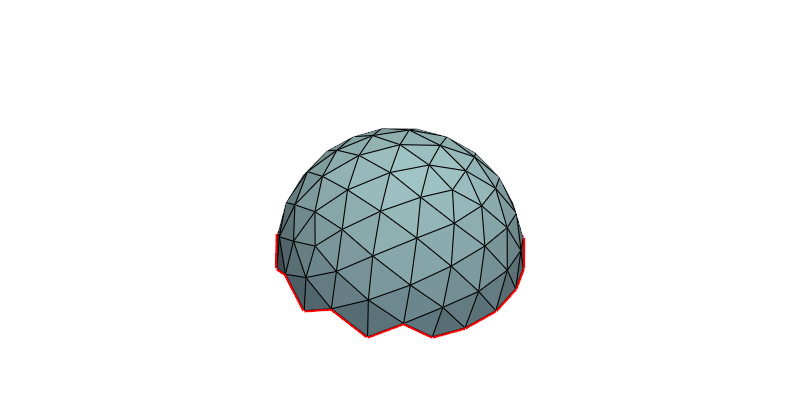

In [14]:
plotter = pv.Plotter()
hemisphere.draw(alpha_points=0.0, ax=plotter, show=False)
plotter.add_mesh(to_pyvista(hemisphere.get_boundary_mesh()), color="red", line_width=4)
plotter.show()

### Non-Manifold Meshes

Three small meshes show the defects that `is_manifold()` detects:

- A non-manifold edge: three triangles share one edge.
- A pinch vertex on a surface: two triangles meet only at one vertex (a
  "bowtie").
- A pinch vertex in a volume: two tetrahedra meet only at one vertex.

In [15]:
three_on_one_edge = Mesh(
    points=torch.tensor(
        [
            [0.0, 0.0, 0.0],
            [1.0, 0.0, 0.0],
            [0.5, 1.0, 0.0],
            [0.5, -1.0, 0.0],
            [0.5, 0.0, 1.0],
        ]
    ),
    cells=torch.tensor([[0, 1, 2], [1, 0, 3], [0, 1, 4]]),
)
bowtie = Mesh(
    points=torch.tensor([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0]]),
    cells=torch.tensor([[0, 1, 2], [0, 3, 4]]),
)
two_tets = Mesh(
    points=torch.tensor(
        [
            [0.0, 0.0, 0.0],  # shared vertex
            [1.0, 0.0, 0.0],
            [0.0, 1.0, 0.0],
            [0.0, 0.0, 1.0],
            [-1.0, 0.0, 0.0],
            [0.0, -1.0, 0.0],
            [0.0, 0.0, -1.0],
        ]
    ),
    cells=torch.tensor([[0, 1, 2, 3], [0, 4, 5, 6]]),
)

for name, m in [
    ("three triangles on one edge", three_on_one_edge),
    ("bowtie", bowtie),
    ("two tets at one vertex", two_tets),
]:
    print(f"{name:28s} manifold={m.is_manifold()}")

three triangles on one edge  manifold=False
bowtie                       manifold=False
two tets at one vertex       manifold=False


`is_manifold(check_level=...)` sets how far the check goes:

- `"facets"` checks only that no facet has more than two cells.
- `"edges"` also checks the edge neighborhoods of tetrahedral meshes.
- `"full"` (the default) also checks the vertex neighborhoods.

The facet check alone catches the first mesh but not the pinch vertices.

In [16]:
for name, m in [("three triangles on one edge", three_on_one_edge), ("bowtie", bowtie)]:
    print(f"{name:28s} facets-only manifold={m.is_manifold(check_level='facets')}")

three triangles on one edge  facets-only manifold=False
bowtie                       facets-only manifold=True


### Volume Meshes

A tetrahedral mesh of a solid always has boundary triangles, so it is never
watertight. To check that a volume mesh encloses a closed region, check its
boundary surface instead.

In [17]:
cube = cube_volume.load(subdivisions=3)
print(
    f"cube volume:   watertight={cube.is_watertight()}  manifold={cube.is_manifold()}"
)
print(f"cube boundary: watertight={cube.get_boundary_mesh().is_watertight()}")

cube volume:   watertight=False  manifold=True
cube boundary: watertight=True


### A Real Asset: The Stanford Bunny

The bunny used in these tutorials passes `validate()`, but the topology
checks show that it is open and non-manifold.

In [18]:
print(f"valid:      {bunny.validate()['valid']}")
print(f"watertight: {bunny.is_watertight()}")
print(f"manifold:   {bunny.is_manifold()}")

bunny_boundary = bunny.get_boundary_mesh()
boundary_edges_per_point = torch.bincount(
    bunny_boundary.cells.flatten(), minlength=bunny.n_points
)
print(f"boundary edges: {bunny_boundary.n_cells}")
print(f"points on 4 boundary edges: {(boundary_edges_per_point == 4).sum().item()}")

valid:      True
watertight: False
manifold:   False
boundary edges: 12
points on 4 boundary edges: 1


The bunny has 12 boundary edges. They form two small holes that touch at one
vertex, and that vertex is a pinch vertex like the bowtie's. The view below
looks at the holes, with the boundary edges in red.

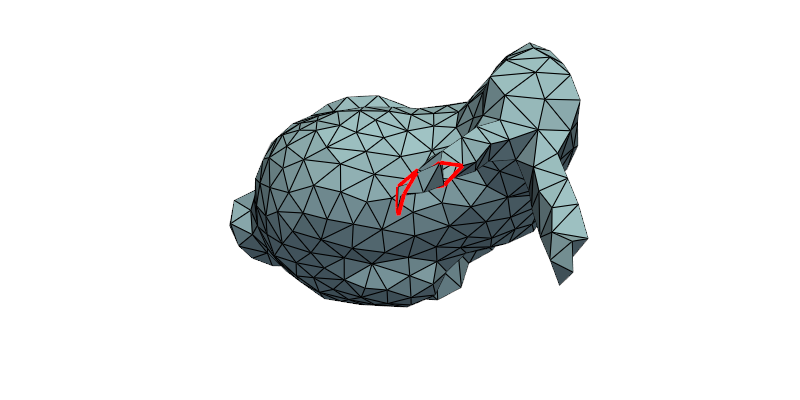

In [19]:
hole_points = bunny.points[bunny_boundary.cells.unique()]
view_direction = hole_points.mean(0) - bunny.points.mean(0)

plotter = pv.Plotter()
bunny.draw(alpha_points=0.0, ax=plotter, show=False)
plotter.add_mesh(to_pyvista(bunny_boundary), color="red", line_width=4)
plotter.view_vector(view_direction.tolist())
plotter.camera.zoom(1.5)
plotter.show()

## 5. Repairing a Mesh

The `physicsnemo.mesh.repair` module has one function for each repair in the
bottom row of the figure in Section 3, and a pipeline that runs several of
them in order.

### Merge Duplicate Points with `clean()`

An STL file stores each triangle with its own three vertices, so adjacent
triangles do not share points. Such a "triangle soup" has every edge on the
boundary. Build one from the sphere and check it.

In [20]:
sphere = sphere_icosahedral.load(subdivisions=3)
soup = Mesh(
    points=sphere.points[sphere.cells].reshape(-1, 3),
    cells=torch.arange(3 * sphere.n_cells).reshape(-1, 3),
)
print(f"sphere: {sphere.n_points} points, watertight={sphere.is_watertight()}")
print(f"soup:   {soup.n_points} points, watertight={soup.is_watertight()}")

sphere: 642 points, watertight=True
soup:   3840 points, watertight=False


`clean()` merges points closer than `tolerance` (default `1e-12`), removes
duplicate cells, and drops points that no cell uses. Merging restores the
shared vertices, and the sphere is watertight again. If coordinates went
through single precision or a text format, coincident points can differ by
round-off. Pass a larger `tolerance` in that case, in the units of the mesh.

In [21]:
cleaned = soup.clean()
print(f"cleaned: {cleaned.n_points} points, watertight={cleaned.is_watertight()}")

cleaned: 642 points, watertight=True


### Run Several Repairs with `repair_mesh()`

`repair_mesh()` runs the repair operations in a fixed order and reports what
each one did:

1. Remove degenerate cells (`remove_degenerates=True`)
2. Merge duplicate points (`merge_points=True`)
3. Remove isolated points (`remove_isolated=True`)
4. Fix orientation (`fix_orientation=False` by default)
5. Fill holes (`fill_holes=False` by default)

Corrupt a copy of the bunny with 10 duplicate points and one degenerate
triangle, then validate, repair, and validate again.

In [22]:
corrupted = Mesh(
    points=torch.cat([bunny.points, bunny.points[:10]]),
    cells=torch.cat([bunny.cells, torch.tensor([[0, 0, 1]])]),
)
report = corrupted.validate()
print(
    f"valid={report['valid']}  duplicate pairs={report['n_duplicate_vertices']}  degenerate cells={report['n_degenerate_cells']}"
)

repaired, stats = repair_mesh(corrupted)
print(f"points: {corrupted.n_points} -> {repaired.n_points}")
print(f"cells:  {corrupted.n_cells} -> {repaired.n_cells}")
for operation, operation_stats in stats.items():
    print(f"  {operation}: {operation_stats}")
print(f"valid after repair: {repaired.validate()['valid']}")

valid=False  duplicate pairs=10  degenerate cells=1
points: 410 -> 400
cells:  793 -> 792
  degenerates: {'n_zero_area_cells': 1, 'n_duplicate_vertex_cells': 1, 'n_cells_original': 793, 'n_cells_final': 792}
  merge_points: {'n_points_original': 410, 'n_points_final': 400, 'n_duplicates_merged': 10}
  clean: {'n_points_before_merge': 410, 'n_points_after_merge': 400}
  isolated: {'n_isolated_removed': 0, 'n_points_original': 400, 'n_points_final': 400}
valid after repair: True


The point merge runs through `clean_mesh()`, so its own statistics appear
twice: summarized under `merge_points`, and as returned by `clean_mesh()` under
`clean`. `repair_mesh()` merges points closer than `tolerance=1e-6` by
default, while `clean()` uses `tolerance=1e-12`.

### Make the Winding Consistent with `fix_orientation()`

The order of a triangle's vertices sets the direction of its normal. If
neighboring triangles wind in opposite directions, their normals point to
opposite sides of the surface. Point normals, curvature signs, and flux
integrals are then wrong. Flip every third triangle of the sphere to simulate
this.

In [23]:
flipped_cells = sphere.cells.clone()
flipped_cells[::3] = flipped_cells[::3].flip(-1)
scrambled = Mesh(points=sphere.points, cells=flipped_cells)


def outwardness(m):
    """Cosine between each cell normal and the outward radial direction."""
    radial = torch.nn.functional.normalize(m.cell_centroids, dim=-1)
    return (m.cell_normals * radial).sum(-1)


print(
    f"outward-facing cells: {(outwardness(scrambled) > 0).sum().item()} of {scrambled.n_cells}"
)

outward-facing cells: 853 of 1280


`fix_orientation()` makes each connected component follow the winding of
its lowest-index cell. This example flipped cell 0, so every cell now faces
inward. The winding is consistent, but not necessarily outward. For a
closed surface, flip all cells if the result faces the wrong way.

In [24]:
oriented, stats = fix_orientation(scrambled)
print(stats)
print(
    f"outward-facing cells: {(outwardness(oriented) > 0).sum().item()} of {oriented.n_cells}"
)

outward = Mesh(points=oriented.points, cells=oriented.cells.flip(-1))
print(
    f"after flipping all:   {(outwardness(outward) > 0).sum().item()} of {outward.n_cells}"
)

{'n_cells_flipped': 853, 'n_faces_flipped': 853, 'n_components': 1, 'largest_component_size': 1280, 'n_non_orientable_components': 0}
outward-facing cells: 0 of 1280
after flipping all:   1280 of 1280


Color each cell by `outwardness`, before and after the repair. Blue marks
the cells that face outward, and red marks the cells that face inward.

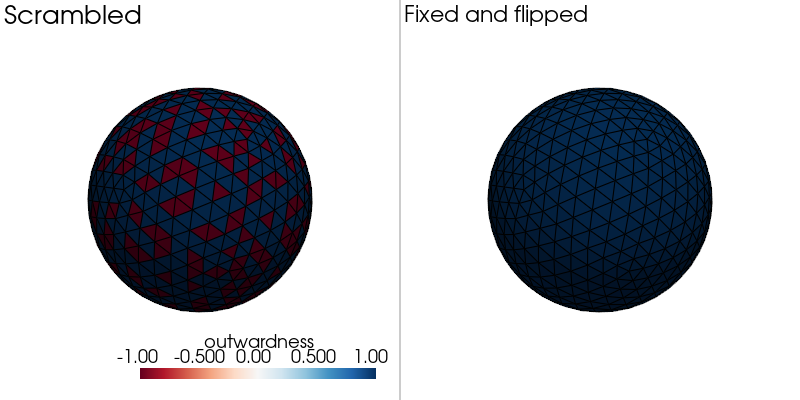

In [25]:
scrambled.cell_data["outwardness"] = outwardness(scrambled)
outward.cell_data["outwardness"] = outwardness(outward)

plotter = pv.Plotter(shape=(1, 2))
for column, (title, m) in enumerate(
    [("Scrambled", scrambled), ("Fixed and flipped", outward)]
):
    plotter.subplot(0, column)
    m.draw(
        cell_scalars="outwardness",
        cmap="RdBu",
        vmin=-1.0,
        vmax=1.0,
        alpha_points=0.0,
        ax=plotter,
        show=False,
    )
    plotter.add_text(title, font_size=12)
plotter.link_views()
plotter.show()

Some surfaces cannot be oriented at all. A Möbius strip has one side, so no
choice of winding is consistent. `fix_orientation()` leaves such a
component as given and counts it. The bunny has the same problem in a
small region. Four of its interior edges are wound the same way by both of
their triangles, and no flip of cells fixes all four.

In [26]:
_, strip_stats = fix_orientation(mobius_strip.load())
_, bunny_stats = fix_orientation(bunny)
print(
    f"Möbius strip non-orientable components: {strip_stats['n_non_orientable_components']}"
)
print(
    f"bunny non-orientable components:        {bunny_stats['n_non_orientable_components']}"
)

Möbius strip non-orientable components: 1
bunny non-orientable components:        1


### Close Holes with `fill_holes()`

`fill_holes()` finds each closed loop of boundary edges on a triangle mesh and
fills it with a fan of triangles around a new center point. By default, it
leaves holes with more than `max_hole_edges=10` edges open, so that it does
not close an intended opening such as an inlet. Cut a cap off the sphere to
make a hole of 18 edges, then fill it with the default and with a raised
limit.

In [27]:
holey = sphere.slice_cells(sphere.cell_centroids[:, 2] < 0.9)
print(
    f"watertight={holey.is_watertight()}, boundary edges={holey.get_boundary_mesh().n_cells}"
)

_, default_stats = fill_holes(holey)
print(f"default:            {default_stats}")

filled, stats = fill_holes(holey, max_hole_edges=20)
print(f"max_hole_edges=20:  {stats}")
print(f"watertight after filling: {filled.is_watertight()}")

watertight=False, boundary edges=18
default:            {'n_holes_detected': 1, 'n_holes_filled': 0, 'n_holes_skipped': 1, 'n_faces_added': 0, 'n_points_added': 0}
max_hole_edges=20:  {'n_holes_detected': 1, 'n_holes_filled': 1, 'n_holes_skipped': 0, 'n_faces_added': 18, 'n_points_added': 1}
watertight after filling: True


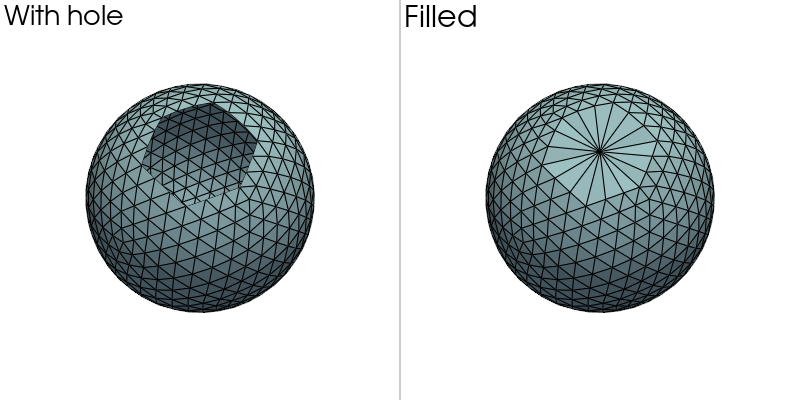

In [28]:
plotter = pv.Plotter(shape=(1, 2))
for column, (title, m) in enumerate([("With hole", holey), ("Filled", filled)]):
    plotter.subplot(0, column)
    m.draw(alpha_points=0.0, ax=plotter, show=False)
    plotter.add_text(title, font_size=12)
    plotter.view_vector([0.3, 0.3, 1.0])
plotter.link_views()
plotter.show()

`fill_holes()` follows each loop through points that have exactly two
boundary edges. The bunny's two holes meet at a pinch vertex with four
boundary edges, so `fill_holes()` finds no loop to fill there.

In [29]:
_, bunny_hole_stats = fill_holes(bunny, max_hole_edges=20)
print(bunny_hole_stats)

{'n_holes_detected': 0, 'n_holes_filled': 0, 'n_holes_skipped': 0, 'n_faces_added': 0, 'n_points_added': 0}


## Summary

This tutorial covered the following points:

- `quality_metrics` scores each cell, and `statistics` summarizes a mesh as
  `(min, mean, max, std)`.
- `validate()` finds bad indices, duplicate points, and degenerate cells.
  `is_watertight()` and `is_manifold()` check topology. A volume mesh is never
  watertight, so check its boundary surface instead.
- `clean()` and `repair_mesh()` merge points and remove bad cells.
  `fix_orientation()` makes the winding consistent, and `fill_holes()` closes
  small boundary loops.

## Next Steps

Continue with the following resources:

- API Reference:
  [validation](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/validation.html),
  [repair](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/repair.html),
  and [boundaries](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/boundaries.html).
- User Guide:
  [Using Mesh](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/using_mesh.html).

**Next:** [Tutorial 8: Simulation Domains with DomainMesh](tutorial_8_domain_mesh.ipynb)
keeps the flow past a cylinder, its wall, and its far field in one object.